# Q2: Exploratory Data Analysis of Laptop Prices

**Mini-Project 1 · Neuroscience Data Analysis with Python**

We investigate a dataset of laptops (manufacturer, specifications, operating system and price) and write a short analytical report for someone considering the laptop market.

| Section | Owner |
|---|---|
| A. Data audit and preparation | Yahli |
| B. Data cleaning and feature construction | Yahli |
| C. Investigating the data | Yahli |
| D. Unusual observations | Junia |
| E. Scientific interpretation | Yahli |

## Setup

In [27]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("laptop-price-dataset.csv")

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")


def save_fig(fig, name):
    """Save a figure to figures/ with a consistent naming scheme (q2_<name>.png)."""
    path = FIG_DIR / f"q2_{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path


df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()   # all cleaning is done on this copy; df_raw stays untouched for comparison
print(df.shape)
df.head()

(1275, 15)


,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60


## A. Data audit and preparation
*Owner: Yahli*

Before analyzing, we investigate structure and quality:
- [x] What does each row represent?
- [x] What variables are available?
- [x] Which columns are numerical and which are categorical?
- [x] Are there missing values, duplicates or suspicious observations?
- [x] Are the data types appropriate for the intended analysis?
- [x] Are units and price ranges plausible?

<div dir="rtl">

**איך הסעיף בנוי:** לפני כל תא קוד כתוב למה עושים אותו, ואחריו מה רואים בפלט.
בסוף הסעיף יש טבלה של כל הבעיות שמצאנו, ולכל אחת: האם מטפלים בה ולמה.
בסעיף הזה **לא משנים כלום** בנתונים. רק בודקים.

</div>

### A.1 Rows and columns

<div dir="rtl">

**למה:** לפני כל ניתוח צריך לדעת מה כל שורה מייצגת ומה הסוג של כל עמודה.
עמודה מספרית שנטענה כטקסט (למשל `"8GB"` במקום `8`) לא מאפשרת לחשב ממוצע או קורלציה.

</div>

In [28]:
# Size and column types
print("Rows, columns:", df.shape)

numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
print("\nNumeric columns:", numeric_cols)
print("\nCategorical (text) columns:", categorical_cols)

df.dtypes

Rows, columns: (1275, 15)

Numeric columns: ['Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)', 'Price (Euro)']

Categorical (text) columns: ['Company', 'Product', 'TypeName', 'ScreenResolution', 'CPU_Company', 'CPU_Type', 'Memory', 'GPU_Company', 'GPU_Type', 'OpSys']


Company                 object
Product                 object
TypeName                object
Inches                 float64
ScreenResolution        object
CPU_Company             object
CPU_Type                object
CPU_Frequency (GHz)    float64
RAM (GB)                 int64
Memory                  object
GPU_Company             object
GPU_Type                object
OpSys                   object
Weight (kg)            float64
Price (Euro)           float64
dtype: object

<div dir="rtl">

**מה רואים:**
- **כל שורה היא דגם אחד של מחשב נייד:** יצרן, שם דגם, מפרט ומחיר באירו. יש 1,275 שורות ו-15 עמודות, כמו בתוכנית העבודה.
- **5 עמודות מספריות:** `Inches`, `CPU_Frequency (GHz)`, `RAM (GB)`, `Weight (kg)`, `Price (Euro)`. היחידות כתובות בשם העמודה, והערכים כבר נטענו כמספרים (`int64` / `float64`). לכן **אין צורך להמיר סוגים**.
- **10 עמודות קטגוריות (טקסט).** אחת מהן, `Memory`, מערבבת שני דברים בטקסט אחד: גודל וסוג של האחסון (`"256GB SSD"`). אותה נפרק בסעיף B.2.

</div>

### A.2 Missing values and duplicates

<div dir="rtl">

**למה:** ערך חסר יכול לשבש ממוצעים וגרפים. שורה כפולה נספרת פעמיים ומטה את התוצאות.

</div>

In [29]:
# Missing values in each column
print("Missing values per column:")
print(df.isna().sum())

# Exact duplicates: rows that are identical in all 15 columns
print("\nExact duplicate rows:", df.duplicated().sum())

Missing values per column:
Company                0
Product                0
TypeName               0
Inches                 0
ScreenResolution       0
CPU_Company            0
CPU_Type               0
CPU_Frequency (GHz)    0
RAM (GB)               0
Memory                 0
GPU_Company            0
GPU_Type               0
OpSys                  0
Weight (kg)            0
Price (Euro)           0
dtype: int64

Exact duplicate rows: 0


<div dir="rtl">

**מה רואים:** אין אף ערך חסר (0 בכל העמודות), ואין שורות זהות לגמרי. שני הממצאים מתוכנית העבודה מאומתים.

**עכשיו כפילויות כמעט-זהות:** שורות שזהות בכל 14 העמודות **חוץ מהמחיר**, כלומר אותו מחשב עם שני מחירים.
`keep=False` מסמן את **שתי** השורות בכל זוג, ולא רק את השנייה.

</div>

In [30]:
# Near duplicates: rows identical in every column except the price
spec_cols = [col for col in df.columns if col != "Price (Euro)"]
same_spec = df[df.duplicated(subset=spec_cols, keep=False)]
print("Rows that have a twin with the same specs:", len(same_spec))

# Show each pair once, with its two prices
pairs = same_spec.groupby(spec_cols)["Price (Euro)"].agg(["count", "min", "max"]).reset_index()
pairs["difference"] = (pairs["max"] - pairs["min"]).round(2)
print("Number of pairs:", len(pairs))

pairs[["Company", "Product", "TypeName", "RAM (GB)", "Memory", "min", "max", "difference"]].sort_values("difference")

Rows that have a twin with the same specs: 48
Number of pairs: 24


,Company,Product,TypeName,RAM (GB),Memory,min,max,difference
2,Dell,Inspiron 5570,Notebook,8,256GB SSD,797.41,800.00,2.59
9,Dell,XPS 15,Notebook,8,256GB SSD,1820.00,1829.00,9.00
1,Dell,Inspiron 5370,Ultrabook,8,256GB SSD,931.88,955.00,23.12
10,HP,EliteBook 1040,Notebook,8,256GB SSD,1469.00,1513.00,44.00
13,Lenovo,IdeaPad 320-15ABR,Notebook,6,256GB SSD,549.00,597.57,48.57
3,Dell,Inspiron 5570,Notebook,8,256GB SSD,870.00,919.00,49.00
16,Lenovo,ThinkPad Yoga,2 in 1 Convertible,8,512GB SSD,1970.00,2025.00,55.00
5,Dell,Inspiron 5770,Notebook,8,128GB SSD + 1TB HDD,1085.00,1142.00,57.00
17,Lenovo,Thinkpad X270,Ultrabook,8,256GB SSD,1584.00,1650.00,66.00
0,Acer,Aspire 7,Notebook,8,1TB HDD,779.00,846.00,67.00


<div dir="rtl">

**מה רואים:** 48 שורות שיוצרות **24 זוגות**. בכל זוג המפרט זהה לגמרי, אבל המחיר שונה.
הפער הקטן ביותר הוא €2.59 (Inspiron 5570) והגדול ביותר €369.58 (XPS 15).

אלה לא בהכרח טעויות: אותו דגם יכול להימכר בשני מחירים (חנויות שונות, תאריכים שונים, או הבדל שלא מופיע בטבלה, כמו צבע או אחריות).
**אין לנו דרך לדעת איזה מחיר נכון**, ולכן לא מוחקים. ההחלטה כתובה בטבלה בסוף הסעיף.

</div>

### A.3 Ranges of the numeric columns

<div dir="rtl">

**למה:** בודקים שהיחידות והטווחים הגיוניים. מחיר שלילי, משקל של 40 ק"ג או מסך של 2 אינץ' היו מעידים על טעות.

</div>

In [31]:
# Min, max, mean and quartiles of every numeric column
print("RAM values:", sorted(df["RAM (GB)"].unique().tolist()))
df[numeric_cols].describe().round(2)

RAM values: [2, 4, 6, 8, 12, 16, 24, 32, 64]


,Inches,CPU_Frequency (GHz),RAM (GB),Weight (kg),Price (Euro)
count,1275.00,1275.0,1275.00,1275.00,1275.00
mean,15.02,2.3,8.44,2.04,1134.97
std,1.43,0.5,5.10,0.67,700.75
min,10.10,0.9,2.00,0.69,174.00
25%,14.00,2.0,4.00,1.50,609.00
50%,15.60,2.5,8.00,2.04,989.00
75%,15.60,2.7,8.00,2.31,1496.50
max,18.40,3.6,64.00,4.70,6099.00


<div dir="rtl">

**היסטוגרמה** מראה את כל ההתפלגות, ולא רק את המינימום והמקסימום. ערכים חריגים מופיעים בה כעמודות בודדות, רחוקות מהשאר.

</div>

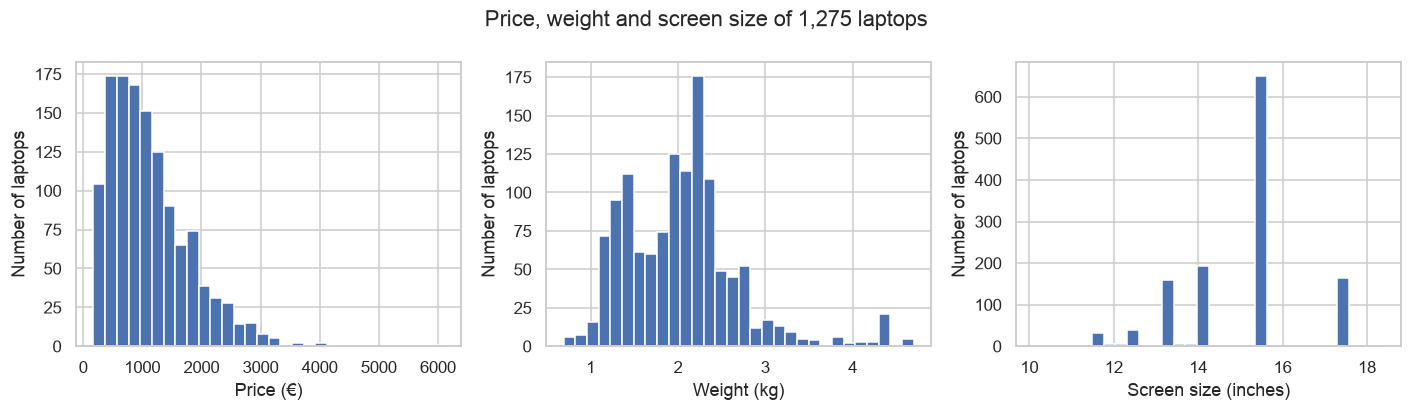

In [32]:
# Distributions of the three columns the work plan asks us to check
columns_to_plot = [("Price (Euro)", "Price (€)"),
                   ("Weight (kg)", "Weight (kg)"),
                   ("Inches", "Screen size (inches)")]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (col, label) in zip(axes, columns_to_plot):
    ax.hist(df[col], bins=30, edgecolor="white")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of laptops")
fig.suptitle("Price, weight and screen size of 1,275 laptops")
fig.tight_layout()
save_fig(fig, "numeric_distributions")
plt.show()

<div dir="rtl">

עכשיו מסתכלים על השורות הקיצוניות עצמן: האם אלה מחשבים אמיתיים או טעויות הקלדה?

</div>

In [33]:
# The most extreme rows: real laptops or typing mistakes?
show_cols = ["Company", "Product", "TypeName", "Inches", "RAM (GB)", "Memory", "Weight (kg)", "Price (Euro)"]

print("Cheapest:")
display(df.nsmallest(3, "Price (Euro)")[show_cols])
print("Most expensive:")
display(df.nlargest(3, "Price (Euro)")[show_cols])
print("Lightest:")
display(df.nsmallest(3, "Weight (kg)")[show_cols])
print("Heaviest:")
display(df.nlargest(3, "Weight (kg)")[show_cols])

Cheapest:


,Company,Product,TypeName,Inches,RAM (GB),Memory,Weight (kg),Price (Euro)
1215,Acer,C740-C9QX (3205U/2GB/32GB/Chrome,Netbook,11.6,2,32GB SSD,1.30,174.0
20,Asus,Vivobook E200HA,Netbook,11.6,2,32GB Flash Storage,0.98,191.9
1120,Vero,V131 (X5-Z8350/4GB/32GB/FHD/W10),Notebook,13.3,4,32GB Flash Storage,1.35,196.0


Most expensive:


,Company,Product,TypeName,Inches,RAM (GB),Memory,Weight (kg),Price (Euro)
196,Razer,Blade Pro,Gaming,17.3,32,1TB SSD,3.49,6099.0
830,Razer,Blade Pro,Gaming,17.3,32,512GB SSD,3.49,5499.0
610,Lenovo,Thinkpad P51,Notebook,15.6,32,1TB SSD,2.50,4899.0


Lightest:


,Company,Product,TypeName,Inches,RAM (GB),Memory,Weight (kg),Price (Euro)
50,Lenovo,Yoga Book,2 in 1 Convertible,10.1,4,64GB Flash Storage,0.69,319.00
1082,Lenovo,Yoga Book,2 in 1 Convertible,10.1,4,64GB Flash Storage,0.69,646.27
1114,Lenovo,Yoga Book,2 in 1 Convertible,10.1,4,64GB Flash Storage,0.69,549.00


Heaviest:


,Company,Product,TypeName,Inches,RAM (GB),Memory,Weight (kg),Price (Euro)
238,Asus,ROG G703VI-E5062T,Gaming,17.3,32,512GB SSD + 1TB HDD,4.7,3890.00
577,Lenovo,IdeaPad Y910-17ISK,Gaming,17.3,32,256GB SSD + 1TB HDD,4.6,2663.00
1048,Lenovo,IdeaPad Y900-17ISK,Gaming,17.3,16,128GB SSD + 1TB HDD,4.6,2289.99


<div dir="rtl">

**מה רואים:**
- **מחיר:** €174 עד €6,099, חציון €989 (כמו בתוכנית העבודה). הממוצע (€1,134.97) גבוה מהחציון, וההיסטוגרמה **מוטה ימינה**: רוב המחשבים זולים יחסית, ומעט מחשבים יקרים מאוד מושכים את הממוצע למעלה. לכן בהמשך כדאי להשתמש ב**חציון**, ולשקול סקאלה לוגריתמית (2C).
- הזול ביותר הוא Chromebook קטן של Acer עם 2GB RAM, והיקר ביותר הוא Razer Blade Pro, מחשב גיימינג יוקרתי. **שניהם הגיוניים.** ערך קיצוני הוא לא בהכרח טעות, וזה הנושא של סעיף D.
- **משקל:** 0.69 ק"ג (Lenovo Yoga Book עם מסך 10.1") עד 4.7 ק"ג (מחשב גיימינג עם מסך 17.3"). הגיוני.
- **מסך:** 10.1 עד 18.4 אינץ'. רוב המחשבים בגדלים המקובלים (15.6, 14, 17.3, 13.3). הגיוני.
- **RAM:** 2 עד 64 GB, ורק בגדלים שקיימים במחשבים אמיתיים. **מעבד:** 0.9 עד 3.6 GHz. הגיוני.
- **מסקנה:** אף ערך מספרי לא נראה כמו טעות יחידות או הקלדה. לכן לא משנים את העמודות המספריות.

</div>

### A.4 Values of the categorical columns

<div dir="rtl">

**למה:** `value_counts()` מראה את כל הערכים השונים בעמודה ובאיזו תדירות כל אחד מופיע.
כך מוצאים **אותו דבר שכתוב בשתי צורות** (שתי קבוצות במקום אחת) וקטגוריות קטנות מדי לניתוח.

</div>

In [34]:
for col in ["Company", "TypeName", "OpSys"]:
    print(df[col].value_counts(), "\n")

Company
Dell         291
Lenovo       289
HP           268
Asus         152
Acer         101
MSI           54
Toshiba       48
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
Fujitsu        3
LG             3
Huawei         2
Name: count, dtype: int64 

TypeName
Notebook              707
Gaming                205
Ultrabook             194
2 in 1 Convertible    117
Workstation            29
Netbook                23
Name: count, dtype: int64 

OpSys
Windows 10      1048
No OS             66
Linux             58
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: count, dtype: int64 



<div dir="rtl">

**מה רואים:**
- **OpSys:** `macOS` (13) ו-`Mac OS X` (8) הם **אותה מערכת הפעלה בשני שמות** (אפל שינתה את השם). יש שלוש גרסאות של Windows: `Windows 10`, `Windows 10 S` (Windows 10 במצב מוגבל) ו-`Windows 7`. `Android` מופיע רק ב-2 מחשבים. `No OS` (66) **הוא לא ערך חסר**: אלה מחשבים שנמכרים בלי מערכת הפעלה. מטפלים בזה ב-B.1.
- **Company:** 19 יצרנים. שלושת הגדולים (Dell, Lenovo, HP) הם כשני שלישים מהשורות, ולחלק מהיצרנים יש רק 2–4 מחשבים. בהשוואה בין יצרנים צריך לזכור שקבוצה של 2 מחשבים לא מספיקה למסקנה.
- **TypeName:** 6 סוגים, בלי שמות כפולים. `Workstation` (29) ו-`Netbook` (23) הן קבוצות קטנות.

**`Memory`** מקבלת תא משלה, כי יש בה הכי הרבה ערכים שונים.

</div>

In [35]:
print("Different Memory values:", df["Memory"].nunique())
print(df["Memory"].value_counts())

# Rows with two drives. repr() shows hidden spaces that print() does not.
has_plus = df["Memory"].str.contains("+", regex=False)
print("\nRows with two drives ('+'):", has_plus.sum())
print("Example:", repr(df.loc[has_plus, "Memory"].iloc[0]))

Different Memory values: 39
Memory
256GB SSD                        412
1TB HDD                          215
500GB HDD                        124
512GB SSD                        114
128GB SSD +  1TB HDD              94
128GB SSD                         74
256GB SSD +  1TB HDD              73
32GB Flash Storage                36
2TB HDD                           16
512GB SSD +  1TB HDD              14
1TB SSD                           14
64GB Flash Storage                13
256GB SSD +  2TB HDD              10
256GB Flash Storage                8
16GB Flash Storage                 7
1.0TB Hybrid                       7
32GB SSD                           6
180GB SSD                          5
128GB Flash Storage                4
512GB SSD +  2TB HDD               3
16GB SSD                           3
512GB Flash Storage                2
1TB SSD +  1TB HDD                 2
256GB SSD +  500GB HDD             2
128GB SSD +  2TB HDD               2
256GB SSD +  256GB SSD             2
512

<div dir="rtl">

**מה רואים:**
- 39 טקסטים שונים. כל אחד מערבב **גודל** (`256GB`, `1TB`) ו**סוג** (`SSD`, `HDD`, `Flash Storage`, `Hybrid`).
- ב-**208 שורות** יש שני כוננים עם `+`, ו-`repr` חושף שאחרי ה-`+` יש **שני רווחים**: `'128GB SSD +  1TB HDD'`. בהדפסה רגילה קשה לראות את זה, והשוואה פשוטה של טקסט הייתה נכשלת.
- אותו גודל כתוב בשתי צורות: `1TB` ו-`1.0TB`.
- כמה ערכים נראים חשודים: `8GB SSD`, `32GB HDD`, `128GB HDD`. בודקים אותם בתא הבא.

</div>

### A.5 Suspicious values

<div dir="rtl">

**למה:** תוכנית העבודה מנתה כמה בעיות שכדאי לחפש. לא סומכים על הרשימה: בודקים כל אחת בקוד.

</div>

In [36]:
# Storage values that looked strange in the value_counts above
small_storage = df["Memory"].isin(["8GB SSD", "32GB HDD", "128GB HDD"])
df.loc[small_storage, show_cols]

,Company,Product,TypeName,Inches,RAM (GB),Memory,Weight (kg),Price (Euro)
718,Mediacom,Smartbook 142,Notebook,14.0,4,32GB HDD,1.4,265.0
839,Asus,R558UA-DM966T (i5-7200U/8GB/128GB/FHD/W10),Notebook,15.6,8,128GB HDD,2.3,590.0
950,HP,ZBook Studio,Workstation,15.6,8,8GB SSD,2.0,2249.0


<div dir="rtl">

**מה רואים:**
- **`8GB SSD` ב-HP ZBook Studio:** תחנת עבודה (Workstation) ב-€2,249. תחנת עבודה עם 8GB אחסון לא סבירה, ולכן זו כנראה טעות בהזנת הנתונים.
- **`32GB HDD` ב-Mediacom ב-€265:** כונן קשיח (HDD) של 32GB כמעט לא קיים. במחשבים זולים כאלה זה בדרך כלל זיכרון Flash, כלומר כנראה **הסוג** שגוי.
- **`128GB HDD` ב-Asus:** גם כאן HDD קטן באופן חשוד.
- באף אחד מהשלושה **אנחנו לא יודעים מה הערך הנכון.** לכן לא מתקנים, אלא מתעדים ומעבירים לסעיף D (חריגים).
  שימו לב: שיטת IQR על המחיר לא תתפוס את ה-ZBook, כי המחיר שלו רגיל. החריגה שלו היא באחסון.

</div>

In [37]:
# Text problems: a strange GPU name and a spelling mistake in Product
print(df.loc[df["GPU_Type"].str.contains("960"), "GPU_Type"].value_counts())
print()
print(df.loc[df["Product"].str.contains("Insprion"), ["Company", "Product"]])

GPU_Type
GeForce GTX 960M           12
GeForce GTX 960<U+039C>     2
GeForce GTX 960             2
GeForce 960M                1
Name: count, dtype: int64

    Company        Product
948    Dell  Insprion 5767


<div dir="rtl">

**מה רואים:**
- `GeForce GTX 960<U+039C>` (2 שורות): `U+039C` הוא הקוד של האות היוונית **Μ**, שנראית בדיוק כמו M. כשהקובץ נשמר, האות הוחלפה בטקסט של הקוד שלה. זה אותו כרטיס מסך כמו `GeForce GTX 960M` (12 שורות), אבל בלי תיקון הוא ייספר ככרטיס אחר.
- `Insprion 5767` היא טעות כתיב של **Inspiron**, סדרה של Dell. שורה אחת.

</div>

In [38]:
# Product names that were cut in the middle: '(' without a closing ')'
cut_names = df["Product"].str.count(r"\(") != df["Product"].str.count(r"\)")
print("Product names that look cut:", cut_names.sum())
df.loc[cut_names, ["Company", "Product"]].head()

Product names that look cut: 84


,Company,Product
32,HP,17-ak001nv (A6-9220/4GB/500GB/Radeon
42,Asus,X542UQ-GO005 (i5-7200U/8GB/1TB/GeForce
49,Asus,X751NV-TY001T (N4200/4GB/1TB/GeForce
69,Asus,FX753VE-GC093 (i7-7700HQ/12GB/1TB/GeForce
75,Asus,FX503VD-E4022T (i7-7700HQ/8GB/1TB/GeForce


<div dir="rtl">

**מה רואים:** ל-84 מוצרים יש `(` בלי `)`, כלומר השם נחתך באמצע רשימת המפרט שבסוגריים.
אי אפשר לשחזר את החלק החסר. אבל המפרט עצמו נמצא בעמודות האחרות, ובניתוח לא משתמשים ב-`Product`.

</div>

### Problems found and decisions

<div dir="rtl">

| # | בעיה | דוגמה | מטפלים? | למה |
|---|---|---|---|---|
| 1 | ערכים חסרים, שורות זהות לגמרי | 0, 0 | אין צורך | בדקנו ואין. |
| 2 | אותה מערכת הפעלה בשני שמות | `macOS` (13), `Mac OS X` (8) | **כן**, B.1 | אחרת אותה מערכת נספרת כשתי קבוצות. |
| 3 | שלוש גרסאות של Windows | `Windows 10`, `Windows 10 S`, `Windows 7` | **כן**, B.1 | מאחדים למשפחה אחת בעמודה חדשה. הגרסה נשארת ב-`OpSys`. |
| 4 | `No OS` נראה כמו ערך חסר | 66 שורות | לא | זו קטגוריה אמיתית: מחשב שנמכר בלי מערכת הפעלה. |
| 5 | `Memory` מערבבת גודל וסוג | `'128GB SSD +  1TB HDD'` | **כן**, B.2 | צריך עמודת `Storage type` (משימת חובה). |
| 6 | שני רווחים אחרי `+`, ו-`1TB` מול `1.0TB` | 208 שורות עם `+` | **כן**, B.2 | הקוד מטפל בזה (`strip()` והמרה למספר). |
| 7 | אחסון חשוד | `8GB SSD` ב-Workstation ב-€2,249, `32GB HDD`, `128GB HDD` | לא, רק מתעדים | לא יודעים מה הערך הנכון. עובר לסעיף D. |
| 8 | כפילויות כמעט-זהות (אותו מפרט, מחיר שונה) | 24 זוגות, פער של €2.59 עד €369.58 | לא | יכולות להיות מכירות אמיתיות בשני מחירים. אין דרך לדעת איזה מחיר נכון, ומחיקה הייתה בחירה שרירותית. |
| 9 | אות מקודדת | `GeForce GTX 960<U+039C>` (2) | **כן**, B.3 | ברור מה הערך הנכון (`960M`). אחרת הוא נספר ככרטיס אחר. |
| 10 | טעות כתיב | `Insprion 5767` | **כן**, B.3 | התיקון ברור, והשם מופיע בטבלאות (למשל בסעיף D). |
| 11 | שמות מוצר קטועים | 84 שורות עם `(` בלי `)` | לא | אי אפשר לשחזר. המפרט נמצא בעמודות אחרות, ו-`Product` לא משמש בניתוח. |
| 12 | ערכים קיצוניים | Razer Blade Pro ב-€6,099, משקל 4.7 ק"ג | לא | מחשבים אמיתיים (גיימינג), לא טעויות. נבדק בסעיף D. |
| 13 | עמודה שמערבבת כמה פרטים | `ScreenResolution`: `'IPS Panel Retina Display 2560x1600'` | לא | לא נדרשת לשאלות שלנו. |

</div>

## B. Data cleaning and feature construction
*Owner: Yahli*

1. Create a consistent representation of the operating-system categories, and document the mapping.
2. Create a new variable **`Storage type`** that extracts the storage device type from the `Memory` column.
3. Validate that the transformations worked. Code that runs is not proof that it is correct.

<div dir="rtl">

**עיקרון:** בעמודות של B.1 ו-B.2 לא נוגעים. יוצרים **עמודות חדשות** לצידן, כדי שאפשר יהיה להשוות לפני ואחרי.
רק שתי טעויות הטקסט ב-B.3 מתוקנות במקום. בכל מקרה `df_raw` נשאר כמו שהוא, להשוואה.

</div>

### B.1 Operating system mapping

<div dir="rtl">

| ערך מקורי | הופך ל- | למה |
|---|---|---|
| `Windows 10` | `Windows` | הגרסה הנפוצה (1,048 מחשבים). |
| `Windows 10 S` | `Windows` | זה Windows 10 במצב מוגבל, לא מערכת אחרת. |
| `Windows 7` | `Windows` | גרסה ישנה יותר של אותה מערכת. לקונה, ההבדל החשוב הוא בין משפחות (Windows, macOS, Linux...). הגרסה נשארת ב-`OpSys` אם נצטרך אותה. |
| `macOS` | `macOS` | השם הנוכחי. |
| `Mac OS X` | `macOS` | השם הישן של אותה מערכת. |
| `Linux` | `Linux` | בלי שינוי. |
| `Chrome OS` | `Chrome OS` | מערכת נפרדת, בלי שינוי. |
| `Android` | `Android` | מערכת נפרדת. רק 2 מחשבים, ולכן לא מסיקים עליה מסקנות לבד. |
| `No OS` | `No OS` | קטגוריה אמיתית, לא ערך חסר. לא הופכים אותה ל-`NaN`. |

את `OpSys` לא משנים. יוצרים עמודה חדשה בשם `OS`.

</div>

In [39]:
# One name for each operating system (decisions and reasons in the table above)
OS_MAP = {
    "Windows 10": "Windows",
    "Windows 10 S": "Windows",
    "Windows 7": "Windows",
    "macOS": "macOS",
    "Mac OS X": "macOS",
    "Linux": "Linux",
    "Chrome OS": "Chrome OS",
    "Android": "Android",
    "No OS": "No OS",
}

# New column. The original OpSys column stays as it is, so nothing is lost.
df["OS"] = df["OpSys"].map(OS_MAP)
df["OS"].value_counts()

OS
Windows      1101
No OS          66
Linux          58
Chrome OS      27
macOS          21
Android         2
Name: count, dtype: int64

<div dir="rtl">

**מה רואים:** 6 קטגוריות במקום 9. `Windows` = 1,101 (1,048 + 8 + 45), ו-`macOS` = 21 (13 + 8).

**הוכחה שזה עבד.** "הקוד רץ" זו לא הוכחה. לכן ארבע בדיקות עם `assert`: אם בדיקה נכשלת, התא עוצר עם הודעה שמסבירה מה לא תקין.

</div>

In [40]:
# Check 1: every original value is in the dictionary.
# map() gives NaN for a value it does not know, so NaN = a value we forgot.
forgotten = df.loc[df["OS"].isna(), "OpSys"].unique()
assert df["OS"].notna().all(), f"Values missing from OS_MAP: {forgotten}"

# Check 2: each original value goes to exactly ONE new value
os_table = pd.crosstab(df["OpSys"], df["OS"])
assert ((os_table > 0).sum(axis=1) == 1).all(), "an original value went to two categories"

# Check 3: no rows were lost, and the counts add up
assert len(df) == len(df_raw)
assert (df["OS"] == "macOS").sum() == df_raw["OpSys"].isin(["macOS", "Mac OS X"]).sum()      # 13 + 8
assert (df["OS"] == "Windows").sum() == df_raw["OpSys"].str.startswith("Windows").sum()   # 1048 + 8 + 45

# Check 4 (known answer): all Apple laptops are macOS, and only Apple laptops are macOS
assert (df.loc[df["Company"] == "Apple", "OS"] == "macOS").all()
assert (df.loc[df["OS"] == "macOS", "Company"] == "Apple").all()

print("All OS checks passed")
os_table

All OS checks passed


OS,Android,Chrome OS,Linux,No OS,Windows,macOS
OpSys,,,,,,
Android,2,0,0,0,0,0
Chrome OS,0,27,0,0,0,0
Linux,0,0,58,0,0,0
Mac OS X,0,0,0,0,0,8
No OS,0,0,0,66,0,0
Windows 10,0,0,0,0,1048,0
Windows 10 S,0,0,0,0,8,0
Windows 7,0,0,0,0,45,0
macOS,0,0,0,0,0,13


<div dir="rtl">

**מה רואים:** כל הבדיקות עברו. בטבלת ה-`crosstab` (ערך מקורי בשורות, ערך חדש בעמודות) בכל שורה יש מספר בעמודה **אחת** בלבד,
כלומר כל ערך מקורי הלך לקטגוריה אחת. אין עמודה של `NaN`, כלומר אף ערך לא נשכח במילון.

</div>

### B.2 Storage type

<div dir="rtl">

בעמודה `Memory` כל כונן כתוב כ"גודל סוג" (`'256GB SSD'`), ובמחשב עם שני כוננים יש `+` ביניהם.

**ההחלטות:**
- **שני כוננים מסוגים שונים** → קטגוריה משולבת, למשל `'SSD + HDD'`. למה קטגוריה נפרדת: אלה 200 מחשבים (כ-16%), והם שונים ממחשב עם SSD בלבד, כי יש להם גם מהירות (SSD) וגם נפח גדול (HDD).
- **שני כוננים מאותו סוג** (`'256GB SSD +  256GB SSD'`) → `'SSD'`. סוג האחסון לא משתנה.
- **`Hybrid`** (כונן שמשלב SSD קטן ו-HDD) נשאר סוג בפני עצמו, כי כך הוא כתוב בנתונים.
- **בנוסף (אופציונלי):** `Storage (GB)`, נפח כולל. `1TB` = 1000GB (כמו שיצרנים סופרים), כך ש-`'1TB'` ו-`'1.0TB'` נותנים אותו מספר.
- **סוג לא מוכר** גורם לשגיאה (`ValueError`), ולא לערך ריק בשקט. כך שגיאה שקטה הופכת לשגיאה רועשת.

**למה פונקציות:** אותו פירוק של הטקסט משמש גם לסוג וגם לגודל. לכן כותבים אותו פעם אחת (`parse_memory`), ושתי הפונקציות האחרות משתמשות בו (DRY).

</div>

In [41]:
STORAGE_KINDS = ["SSD", "HDD", "Flash Storage", "Hybrid"]


def parse_memory(memory):
    """Split a Memory text into drives.

    '128GB SSD +  1TB HDD' -> [(128.0, 'SSD'), (1000.0, 'HDD')]
    Size is in GB (1TB = 1000GB). Raises ValueError for text we do not understand.
    """
    drives = []
    for part in memory.split("+"):
        size_text, kind = part.strip().split(" ", 1)   # '1TB HDD' -> '1TB', 'HDD'
        if kind not in STORAGE_KINDS:
            raise ValueError(f"Unknown storage type {kind!r} in {memory!r}")
        if size_text.endswith("TB"):
            size_gb = float(size_text[:-2]) * 1000      # '1.0TB' -> 1000.0
        elif size_text.endswith("GB"):
            size_gb = float(size_text[:-2])             # '256GB' -> 256.0
        else:
            raise ValueError(f"Unknown size {size_text!r} in {memory!r}")
        drives.append((size_gb, kind))
    return drives


def storage_type(memory):
    """Storage type(s) without repeats: '128GB SSD +  1TB HDD' -> 'SSD + HDD'."""
    kinds = []
    for size_gb, kind in parse_memory(memory):
        if kind not in kinds:          # '256GB SSD +  256GB SSD' -> just 'SSD'
            kinds.append(kind)
    return " + ".join(kinds)


def storage_total_gb(memory):
    """Total storage in GB: '128GB SSD +  1TB HDD' -> 1128.0"""
    return sum(size_gb for size_gb, kind in parse_memory(memory))

<div dir="rtl">

**בדיקות עם תשובה ידועה (ground truth):** לפני שמריצים על 1,275 שורות, בודקים את הפונקציות על דוגמאות שאנחנו יודעים מה התשובה שלהן.
בוחרים בכוונה את המקרים הקשים: שני רווחים, אותו סוג פעמיים, `1.0TB` וסוג לא מוכר.

</div>

In [42]:
assert storage_type("256GB SSD") == "SSD"
assert storage_type("64GB Flash Storage") == "Flash Storage"
assert storage_type("128GB SSD +  1TB HDD") == "SSD + HDD"      # two spaces after '+'
assert storage_type("256GB SSD +  256GB SSD") == "SSD"           # same type twice
assert storage_type("1.0TB Hybrid") == "Hybrid"
assert storage_total_gb("1TB HDD") == storage_total_gb("1.0TB HDD") == 1000
assert storage_total_gb("128GB SSD +  1TB HDD") == 1128

# An unknown type must stop the code, not pass silently
try:
    storage_type("256GB Floppy")
    raise AssertionError("an unknown type was accepted")
except ValueError:
    pass

print("All known-answer tests passed")

All known-answer tests passed


<div dir="rtl">

**מה רואים:** כל הבדיקות עברו, כולל הבדיקה שסוג לא מוכר עוצר את הקוד עם `ValueError`.

עכשיו מפעילים את הפונקציות על כל שורה עם `apply`, ויוצרים שתי עמודות חדשות.

</div>

In [43]:
df["Storage type"] = df["Memory"].apply(storage_type)
df["Storage (GB)"] = df["Memory"].apply(storage_total_gb)
df["Storage type"].value_counts()

Storage type
SSD                    635
HDD                    359
SSD + HDD              200
Flash Storage           70
Hybrid                   8
SSD + Hybrid             2
Flash Storage + HDD      1
Name: count, dtype: int64

<div dir="rtl">

**מה רואים:** 7 סוגים במקום 39 טקסטים. `SSD + HDD` היא הקטגוריה השלישית בגודלה (200).
`SSD + Hybrid` (2) ו-`Flash Storage + HDD` (1) קטנות מאוד. ב-2C לא נסיק עליהן מסקנות לבד.

**הוכחה שזה עבד:** חמש בדיקות על כל הטבלה, ובסוף `crosstab` בין העמודה הישנה לחדשה.

</div>

In [44]:
# Check 1: no missing or empty values
assert df["Storage type"].notna().all()
assert (df["Storage type"] != "").all()

# Check 2: each Memory text gets exactly ONE Storage type
storage_table = pd.crosstab(df["Memory"], df["Storage type"])
assert ((storage_table > 0).sum(axis=1) == 1).all(), "a Memory value got two types"

# Check 3: the new column and the original text name the same types, row by row.
# Both directions: nothing invented, and nothing forgotten (e.g. a lost second drive).
for memory, kinds in zip(df["Memory"], df["Storage type"]):
    new_kinds = kinds.split(" + ")
    for kind in new_kinds:
        assert kind in memory, f"{kind!r} not found in {memory!r}"
    for kind in STORAGE_KINDS:
        if kind in memory:
            assert kind in new_kinds, f"{kind!r} is in {memory!r} but missing from {kinds!r}"

# Check 4: a combined type (with '+') can only come from a row with two drives
has_plus = df["Memory"].str.contains("+", regex=False)
is_combined = df["Storage type"].str.contains("+", regex=False)
assert has_plus[is_combined].all(), "a combined type in a row with one drive"
print("Rows with '+':", has_plus.sum(),
      "| combined types:", is_combined.sum(),
      "| two drives of the same type:", (has_plus & ~is_combined).sum())

# Check 5: sizes are positive, and '1TB' and '1.0TB' give the same number
assert (df["Storage (GB)"] > 0).all()
assert (df.loc[df["Memory"] == "1TB HDD", "Storage (GB)"] == 1000).all()
assert (df.loc[df["Memory"] == "1.0TB HDD", "Storage (GB)"] == 1000).all()

print("All Storage checks passed")
storage_table

Rows with '+': 208 | combined types: 203 | two drives of the same type: 5
All Storage checks passed


Storage type,Flash Storage,Flash Storage + HDD,HDD,Hybrid,SSD,SSD + HDD,SSD + Hybrid
Memory,,,,,,,
1.0TB HDD,0,0,1,0,0,0,0
1.0TB Hybrid,0,0,0,7,0,0,0
128GB Flash Storage,4,0,0,0,0,0,0
128GB HDD,0,0,1,0,0,0,0
128GB SSD,0,0,0,0,74,0,0
128GB SSD + 1TB HDD,0,0,0,0,0,94,0
128GB SSD + 2TB HDD,0,0,0,0,0,2,0
16GB Flash Storage,7,0,0,0,0,0,0
16GB SSD,0,0,0,0,3,0,0


<div dir="rtl">

**מה רואים:** כל הבדיקות עברו. מתוך 208 השורות עם `+`, ב-203 יש שני סוגים שונים (קטגוריה משולבת), וב-5 יש פעמיים אותו סוג.
בטבלת ה-`crosstab` כל אחד מ-39 הטקסטים המקוריים נמצא בעמודה **אחת** בלבד.

**בדיקה בעין:** 10 שורות אקראיות. 5 עם כונן אחד ו-5 עם שני כוננים, כי המקרים עם `+` הם הקשים
(בדגימה אקראית רגילה הם עלולים לא להופיע בכלל). `random_state=0` מבטיח שבכל הרצה יוצגו אותן שורות.

</div>

In [45]:
one_drive = df[~has_plus].sample(5, random_state=0)
two_drives = df[has_plus].sample(5, random_state=0)
pd.concat([one_drive, two_drives])[["Memory", "Storage type", "Storage (GB)"]]

,Memory,Storage type,Storage (GB)
912,256GB SSD,SSD,256.0
243,256GB SSD,SSD,256.0
753,180GB SSD,SSD,180.0
1069,256GB Flash Storage,Flash Storage,256.0
852,1TB HDD,HDD,1000.0
99,128GB SSD + 1TB HDD,SSD + HDD,1128.0
492,128GB SSD + 1TB HDD,SSD + HDD,1128.0
228,256GB SSD + 500GB HDD,SSD + HDD,756.0
58,256GB SSD + 2TB HDD,SSD + HDD,2256.0
1165,128GB SSD + 1TB HDD,SSD + HDD,1128.0


<div dir="rtl">

**מה רואים:** בכל אחת מ-10 השורות הסוג והנפח מתאימים לטקסט המקורי.
למשל `'256GB SSD +  2TB HDD'` הפך ל-`SSD + HDD` עם 2,256GB (256 + 2,000).

</div>

### B.3 Small text fixes from section A

<div dir="rtl">

**למה:** שתי בעיות מהטבלה בסעיף A שהתיקון שלהן ברור (בעיות 9 ו-10).
`regex=False` אומר ל-pandas לחפש את הטקסט בדיוק כמו שהוא. בלי זה, ה-`+` שבתוך `<U+039C>` היה מתפרש כסימן מיוחד.

</div>

In [46]:
# GPU: '<U+039C>' is the code of a Greek letter that looks exactly like 'M'
df["GPU_Type"] = df["GPU_Type"].str.replace("<U+039C>", "M", regex=False)
# Product: spelling mistake
df["Product"] = df["Product"].str.replace("Insprion", "Inspiron", regex=False)

# Proof
assert not df["GPU_Type"].str.contains("<U+", regex=False).any()
assert not df["Product"].str.contains("Insprion").any()
gtx_960m_before = df_raw["GPU_Type"].isin(["GeForce GTX 960M", "GeForce GTX 960<U+039C>"]).sum()   # 12 + 2
assert (df["GPU_Type"] == "GeForce GTX 960M").sum() == gtx_960m_before

changed = (df["GPU_Type"] != df_raw["GPU_Type"]) | (df["Product"] != df_raw["Product"])
assert changed.sum() == 3, f"expected 3 changed rows, got {changed.sum()}"
print("Rows changed:", changed.sum())
df.loc[changed, ["Company", "Product", "GPU_Type"]]

Rows changed: 3


,Company,Product,GPU_Type
611,Dell,Inspiron 7559,GeForce GTX 960M
948,Dell,Inspiron 5767,Radeon R7 M445
1218,Lenovo,IdeaPad Y700-15ISK,GeForce GTX 960M


<div dir="rtl">

**מה רואים:** בדיוק 3 שורות השתנו: 2 של כרטיס המסך ואחת של שם המוצר. עכשיו יש 14 שורות של `GeForce GTX 960M`.

</div>

### Clean table for sections C and D

<div dir="rtl">

**למה:** בדיקה אחרונה שלא איבדנו שורות, ורשימה של מה שנוסף. הטבלה הנקייה היא `df`, והיא נקודת ההתחלה של סעיפים C ו-D.

</div>

In [47]:
assert len(df) == len(df_raw), "rows were lost during cleaning"
new_cols = [col for col in df.columns if col not in df_raw.columns]
print("Shape before:", df_raw.shape, "| after:", df.shape)
print("New columns:", new_cols)
df.head()

Shape before: (1275, 15) | after: (1275, 18)
New columns: ['OS', 'Storage type', 'Storage (GB)']


,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro),OS,Storage type,Storage (GB)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69,macOS,SSD,128.0
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94,macOS,Flash Storage,128.0
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00,No OS,SSD,256.0
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45,macOS,SSD,512.0
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60,macOS,SSD,256.0


<div dir="rtl">

**מה רואים:** אותן 1,275 שורות, ו-3 עמודות חדשות: `OS`, `Storage type`, `Storage (GB)`.

**הערה לסעיף D:** אפשר להשתמש ישירות ב-`df`. השורה של HP ZBook Studio (`8GB SSD`) היא חריג **באחסון**, לא במחיר.
אפשר למצוא אותה עם `df[df["Storage (GB)"] < 16]`.

</div>

## C. Investigating the data
*Owner: Yahli*

At least three analytical questions, using at least two different types of analysis.
At least one question must investigate the relationship between **RAM and laptop price**.

For each question: (1) why it is interesting, (2) relevant variables and observations, (3) analytical method, (4) visualization, (5) interpretation.

### Question 1: How is RAM related to laptop price?

**1. Why it is interesting:**

**2. Variables and observations:**

**3. Method:**

In [48]:
# TODO (Yahli): analysis + figure for question 1. Save with save_fig(fig, "ram_price").

**5. Interpretation:**

### Question 2: _title_

**1. Why it is interesting:**

**2. Variables and observations:**

**3. Method:**

In [49]:
# TODO (Yahli): analysis + figure for question 2.

**5. Interpretation:**

### Question 3: _title_

**1. Why it is interesting:**

**2. Variables and observations:**

**3. Method:**

In [50]:
# TODO (Yahli): analysis + figure for question 3.

**5. Interpretation:**

## D. Investigating unusual observations
*Owner: Junia*

- How do we define an outlier?
- Which method do we use to identify one?
- Does an unusual value necessarily represent an error?
- How might outliers affect the mean, median, correlation or regression results?

We do **not** remove outliers automatically. We explain the decision and compare results before and after excluding them.

In [51]:
# TODO (Junia): identify outliers (e.g. IQR rule on price) and show them in a table.

In [52]:
# TODO (Junia): compare mean, median and RAM–price correlation with and without the outliers.

### Decision on outliers
<!-- Which are likely errors, which are real (e.g. high-end gaming laptops), and what we do with each. -->

## E. Scientific interpretation: analytical report
*Owner: Yahli*

### What we observed

### What the analysis supports

### What we cannot conclude
<!-- e.g. a correlation between RAM and price does not establish that RAM causes the price difference. -->

### Limitations